# 03 – Kiểm định thống kê (W9)
Ba giả thuyết chính giữ nguyên định nghĩa, Bonferroni cho đúng ba phép kiểm định. Đơn vị phân tích là khách hàng, không phải dòng sản phẩm. Nếu thiếu nhóm hoặc bảng suy biến, báo không đủ điều kiện thay vì coi không có bằng chứng là bằng nhau. Các phân tích độ nhạy tiếp theo mang tính thăm dò.

In [1]:
# 1. Nạp dữ liệu và tổng hợp hành vi khách hàng (W9)
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.customer_features import build_orders, aggregate_orders, classify_market, build_customer_profiles
from src.robustness import safe_market_test, sensitivity_analysis
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

ALPHA = 0.05
N_BOOT = 5000
RANDOM_STATE = 42
# Ba kiểm định hai phía; đơn vị phân tích là khách hàng, không phải dòng sản phẩm.
DATA_DIR = next((p for p in (Path("../data/processed"), Path("data/processed"))
                 if (p / "retail_processed.parquet").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Hãy chạy python -m src.pipeline từ thư mục gốc dự án trước.")

df = pd.read_parquet(DATA_DIR / "retail_processed.parquet")
required = ["customer_id", "invoice", "invoice_date", "country", "quantity", "price",
            "total_amount", "is_cancelled", "stockcode", "region", "shipping_zone", "country_original"]
if not set(required).issubset(df.columns):
    raise ValueError("Thiếu cột: chạy lại python -m src.pipeline với phiên bản mới.")
assert df[required].notna().all().all(), "Dữ liệu thiếu ở cột bắt buộc."
assert np.isfinite(df[["quantity", "price", "total_amount"]].to_numpy()).all()
assert np.allclose(df["total_amount"], df["quantity"] * df["price"])
assert df["is_cancelled"].isin([True, False]).all()
df_valid = df.loc[~df["is_cancelled"].astype(bool)].copy()
assert (df_valid[["quantity", "price", "total_amount"]] > 0).all().all()
snapshot_date = df["invoice_date"].max().normalize() + pd.Timedelta(days=1)

# Một hóa đơn mua hợp lệ = một đơn hàng. Nhãn địa lý dùng country_original (trước nội suy).
orders = build_orders(df_valid)
print(f"Hóa đơn có nhiều timestamp: {(orders['date_count'] > 1).sum():,}")
customer_df = build_customer_profiles(df)
geo_df = customer_df[customer_df["is_uk"].isin(["UK", "International"])].copy()
print(f"Giao dịch: {len(df):,} | Tổng khách: {df['customer_id'].nunique():,} | Khách có đơn mua: {len(customer_df):,}")
print(f"Số khách chỉ có đơn hủy: {df['customer_id'].nunique() - len(customer_df):,}")
display(customer_df["is_uk"].value_counts().rename("Số khách").to_frame())
print(f"Loại khỏi H1/H3: {len(customer_df)-len(geo_df):,} khách Unknown/Mixed; vẫn giữ cho H2.")
# Giữ tên file tương thích dự án; hồ sơ toàn kỳ chỉ dùng phân tích, KHÔNG dùng để dự đoán tương lai.
customer_df.to_parquet(DATA_DIR / "customer_profiles.parquet", index=False)
print("Đã lưu customer_profiles.parquet (hồ sơ mô tả toàn kỳ).")

Hóa đơn có nhiều timestamp: 64
Giao dịch: 794,437 | Tổng khách: 5,876 | Khách có đơn mua: 5,853
Số khách chỉ có đơn hủy: 23


,Số khách
is_uk,
UK,5334
International,500
Mixed,12
Unknown,7


Loại khỏi H1/H3: 19 khách Unknown/Mixed; vẫn giữ cho H2.
Đã lưu customer_profiles.parquet (hồ sơ mô tả toàn kỳ).


=== H1: AOV QUỐC TẾ VS UK ===


,n,median,mean,sd,skew,min,max
is_uk,,,,,,,
International,500,398.520,642.604,894.134,5.431,22.67,9341.26
UK,5334,269.726,360.166,1282.708,54.676,2.95,84236.25


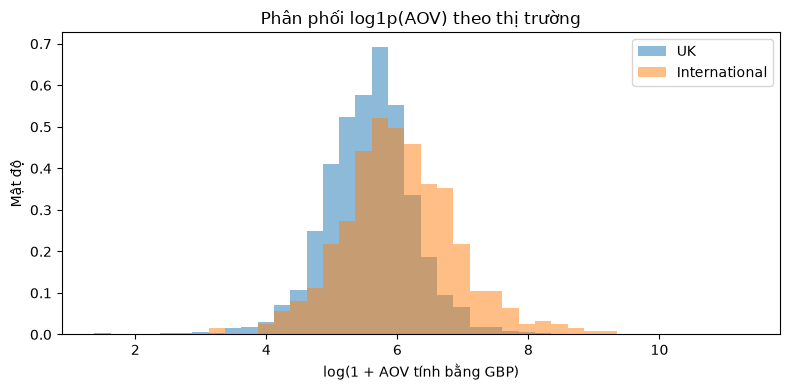

Mann-Whitney U = 1,774,178 | p = 1.9684e-34 | Rank-biserial r = +0.330
Chênh lệch trung vị AOV (Intl - UK): +128.79 GBP (95% CI: [+91.89, +165.07])


In [2]:
# 2. Giả thuyết 1: AOV của International và UK
# H0: Phân phối AOV của hai nhóm giống nhau.
# H1: Hai phân phối khác nhau (kiểm định hai phía, alpha = 0.05).
# Mann-Whitney U phù hợp với dữ liệu lệch phải; không mặc định kiểm định trung vị.
uk_aov = geo_df.loc[geo_df["is_uk"] == "UK", "avg_order_value"].to_numpy()
intl_aov = geo_df.loc[geo_df["is_uk"] == "International", "avg_order_value"].to_numpy()
if min(len(uk_aov), len(intl_aov)) < 2:
    u_stat = p_val_1 = r_rb = median_diff = ci_low_1 = ci_high_1 = np.nan
    print("H1: Không đủ mẫu mỗi nhóm.")
else:
    print("=== H1: AOV QUỐC TẾ VS UK ===")
    # Kiểm tra hình dạng phân phối và giá trị cực trị; Mann-Whitney không yêu cầu chuẩn.
    display(geo_df.groupby("is_uk")["avg_order_value"].agg(
        n="size", median="median", mean="mean", sd="std", skew="skew", min="min", max="max"
    ).round(3))
    fig, ax = plt.subplots(figsize=(8, 4))
    bins = np.histogram_bin_edges(np.log1p(np.concatenate([uk_aov, intl_aov])), bins=40)
    for values, name in [(uk_aov, "UK"), (intl_aov, "International")]:
        ax.hist(np.log1p(values), bins=bins, density=True, alpha=0.5, label=name)
    ax.set(title="Phân phối log1p(AOV) theo thị trường", xlabel="log(1 + AOV tính bằng GBP)", ylabel="Mật độ")
    ax.legend()
    plt.tight_layout()
    plt.show()

    u_stat, p_val_1 = stats.mannwhitneyu(intl_aov, uk_aov, alternative="two-sided")
    n1, n2 = len(intl_aov), len(uk_aov)
    # Rank-biserial r = 2U/(n1*n2) - 1, chiều International - UK.
    r_rb = 2 * u_stat / (n1 * n2) - 1
    rng = np.random.default_rng(RANDOM_STATE)
    boot_diffs = np.array([
        np.median(rng.choice(intl_aov, n1, replace=True)) - np.median(rng.choice(uk_aov, n2, replace=True))
        for _ in range(N_BOOT)
    ])
    median_diff = np.median(intl_aov) - np.median(uk_aov)
    ci_low_1, ci_high_1 = np.quantile(boot_diffs, [ALPHA/2, 1-ALPHA/2])
    print(f"Mann-Whitney U = {u_stat:,.0f} | p = {p_val_1:.4e} | Rank-biserial r = {r_rb:+.3f}")
    print(f"Chênh lệch trung vị AOV (Intl - UK): {median_diff:+.2f} GBP (95% CI: [{ci_low_1:+.2f}, {ci_high_1:+.2f}])")
    # CI bootstrap cho chênh lệch trung vị là ước lượng riêng, không phải CI của U.
    # Một khách chỉ thuộc một nhóm. Tính độc lập giữa các khách là giả định, không thể chứng minh bằng kiểm định chuẩn.

=== H2: CHI TIÊU LOG1P(MONETARY) THEO MÙA VỤ ===


,group,n,mean,sd,skew,excess_kurtosis
0,Peak,2968,6.653,1.216,0.245,0.720
1,Other,2885,6.969,1.515,0.172,0.105


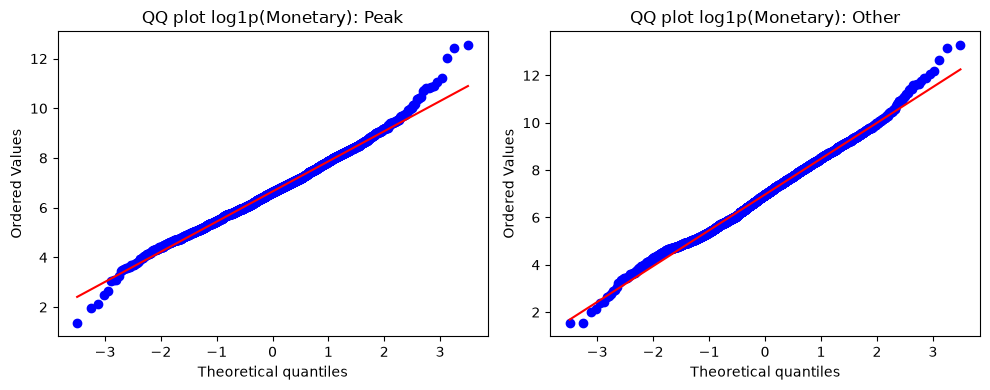

Welch t = -8.773 | df = 5521.2 | p = 2.2899e-18 | Cohen's d = -0.230
Chênh lệch trung bình log (Peak - Other): -0.316 (95% CI: [-0.386, -0.245])
Tỷ số trung bình hình học của (1 + monetary): 0.729


In [3]:
# 3. Giả thuyết 2: Chi tiêu toàn kỳ theo nhóm mùa vụ
# H0: Trung bình log1p(monetary) của hai nhóm bằng nhau.
# H1: Hai trung bình khác nhau. Nhóm cao điểm: >= 50% số đơn vào tháng 9-12.
# monetary là tổng giá trị đơn mua hợp lệ, chưa trừ hoàn trả, không phải chi tiêu riêng mùa cao điểm.
customer_df["peak_group"] = np.where(customer_df["peak_month_ratio"] >= 0.5, "Peak", "Other")
peak_group = np.log1p(customer_df.loc[customer_df["peak_group"] == "Peak", "monetary"].to_numpy())
offpeak_group = np.log1p(customer_df.loc[customer_df["peak_group"] == "Other", "monetary"].to_numpy())
def welch_summary(x, y):
    if min(len(x), len(y)) < 2 or not np.isfinite(x).all() or not np.isfinite(y).all() or (x.var(ddof=1) + y.var(ddof=1) <= 0):
        return (np.nan,) * 7
    nx, ny = len(x), len(y)
    vx, vy = x.var(ddof=1), y.var(ddof=1)
    diff = x.mean() - y.mean()
    a, b = vx/nx, vy/ny
    se = np.sqrt(a+b)
    dof = (a+b)**2 / (a*a/(nx-1) + b*b/(ny-1))
    critical = stats.t.ppf(1-ALPHA/2, dof)
    pooled_sd = np.sqrt(((nx-1)*vx + (ny-1)*vy)/(nx+ny-2))
    test = stats.ttest_ind(x, y, equal_var=False, alternative="two-sided")
    return test.statistic, test.pvalue, dof, diff, diff-critical*se, diff+critical*se, diff/pooled_sd

if min(len(peak_group), len(offpeak_group)) >= 2:
    print("=== H2: CHI TIÊU LOG1P(MONETARY) THEO MÙA VỤ ===")
    # Kiểm tra độ lệch, phương sai và QQ plot; với mẫu lớn, Welch ít nhạy với lệch chuẩn vừa phải.
    shape = pd.DataFrame([{"group": name, "n": len(x), "mean": x.mean(), "sd": x.std(ddof=1),
                           "skew": stats.skew(x, bias=False), "excess_kurtosis": stats.kurtosis(x, bias=False)}
                          for name, x in [("Peak", peak_group), ("Other", offpeak_group)]])
    display(shape.round(3))
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, x, name in zip(axes, [peak_group, offpeak_group], ["Peak", "Other"]):
        stats.probplot(x, dist="norm", plot=ax)
        ax.set_title(f"QQ plot log1p(Monetary): {name}")
    plt.tight_layout()
    plt.show()

t_stat, p_val_2, welch_df, diff_mean, ci_low_2, ci_high_2, cohens_d = welch_summary(peak_group, offpeak_group)
print(f"Welch t = {t_stat:.3f} | df = {welch_df:.1f} | p = {p_val_2:.4e} | Cohen's d = {cohens_d:+.3f}")
print(f"Chênh lệch trung bình log (Peak - Other): {diff_mean:+.3f} (95% CI: [{ci_low_2:+.3f}, {ci_high_2:+.3f}])")
print(f"Tỷ số trung bình hình học của (1 + monetary): {np.exp(diff_mean):.3f}")
# Welch không cần giả định bằng phương sai. Cohen's d dùng SD gộp theo cỡ mẫu.
# Tỷ số trên không phải tỷ số trung bình số học GBP; không kết luận mùa vụ gây thay đổi chi tiêu.

In [4]:
# 4. Giả thuyết 3: Hành vi mua nhiều lần theo thị trường
# H0: Tình trạng mua >= 2 đơn trong kỳ quan sát độc lập với thị trường.
# H1: Hai biến có liên hệ.
ct = pd.crosstab(geo_df["is_uk"], geo_df["is_repeat_buyer"]).reindex(
    index=["UK", "International"], columns=[0, 1], fill_value=0)
chi2_stat, p_val_3, dof, expected, test_3 = safe_market_test(ct)
print("=== H3: TỶ LỆ MUA NHIỀU LẦN (UK VS INTERNATIONAL) ===")
display(ct)
print("Kiểm định:", test_3)
display(pd.DataFrame(expected, index=ct.index, columns=ct.columns).round(2))
# Cramer's V tính từ Pearson chi-square (không hiệu chỉnh Yates), trên đúng mẫu địa lý.
n_uk, n_intl = ct.loc["UK"].sum(), ct.loc["International"].sum()
p_uk = ct.loc["UK", 1] / n_uk if n_uk else np.nan
p_intl = ct.loc["International", 1] / n_intl if n_intl else np.nan
diff_prop = p_uk - p_intl
cramers_v = np.sqrt(chi2_stat / ct.to_numpy().sum()) if ct.to_numpy().sum() else np.nan
# Newcombe CI: kết hợp Wilson score intervals, ổn định hơn Wald ở tỷ lệ gần 0 hoặc 1.
def wilson(p, n):
    if n == 0:
        return np.nan, np.nan
    z = stats.norm.ppf(1-ALPHA/2)
    center = (p + z*z/(2*n))/(1+z*z/n)
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/(1+z*z/n)
    return center-half, center+half

lo_u, hi_u = wilson(p_uk, n_uk)
lo_i, hi_i = wilson(p_intl, n_intl)
ci_low_3 = diff_prop - np.hypot(p_uk-lo_u, hi_i-p_intl)
ci_high_3 = diff_prop + np.hypot(hi_u-p_uk, p_intl-lo_i)
print(f"UK = {p_uk:.2%} | International = {p_intl:.2%}")
print(f"Chênh lệch (UK - Intl): {100*diff_prop:+.2f} điểm % (95% CI: [{100*ci_low_3:+.2f}, {100*ci_high_3:+.2f}])")
print(f"Pearson chi-square = {chi2_stat:.3f} (df={dof}) | {test_3} p = {p_val_3:.4e} | Cramer's V = {cramers_v:.3f}")
# Mua nhiều lần trong kỳ quan sát không đồng nghĩa xác suất quay lại trong tương lai.

=== H3: TỶ LỆ MUA NHIỀU LẦN (UK VS INTERNATIONAL) ===


is_repeat_buyer,0,1
is_uk,,
UK,1466,3868
International,151,349


Kiểm định: Pearson Chi-square


is_repeat_buyer,0,1
is_uk,,
UK,1478.42,3855.58
International,138.58,361.42


UK = 72.52% | International = 69.80%
Chênh lệch (UK - Intl): +2.72 điểm % (95% CI: [-1.33, +7.04])
Pearson chi-square = 1.683 (df=1) | Pearson Chi-square p = 1.9451e-01 | Cramer's V = 0.017


In [5]:
# 5. Kiểm tra biến gây nhiễu: thời gian quan sát và phân tích độ nhạy
# tenure là khoảng cách từ đơn đầu đến đơn cuối, không phải thời lượng có cơ hội mua.
# observation_days đo từ lần mua đầu quan sát được tới ngày kết thúc dữ liệu.
print("=== THỜI GIAN QUAN SÁT VÀ TẦN SUẤT MUA ===")
for group, data in [("peak_group", customer_df), ("is_uk", geo_df)]:
    display(data.groupby(group).agg(
        n=("customer_id", "size"), observation_days_median=("observation_days", "median"),
        tenure_median=("tenure_days", "median"), frequency_median=("frequency", "median"),
        monetary_median=("monetary", "median")
    ).round(2))

# Độ nhạy: chỉ khách có đủ 365 ngày quan sát kể từ ngày mua đầu tiên ghi nhận.
# Mỗi khách có cùng 365 ngày lịch, tính lại toàn bộ chỉ số từ đơn trong cửa sổ đó.
FOLLOWUP_DAYS = 365
first = orders.groupby("customer_id")["invoice_date"].min().dt.normalize().rename("window_start")
windows = first.to_frame()
windows["window_end"] = windows["window_start"] + pd.Timedelta(days=FOLLOWUP_DAYS)

# Loại ngày cuối dataset có thể chưa đủ 24 giờ khi xét cửa sổ hoàn chỉnh.
windows = windows[windows["window_end"] <= df["invoice_date"].max().normalize()]
# Lọc các dòng mua theo chính cửa sổ; không dùng quốc gia được nội suy từ tương lai.
fixed_lines = df_valid.merge(windows.reset_index(), on="customer_id", validate="many_to_one")
fixed_lines = fixed_lines[(fixed_lines["invoice_date"] >= fixed_lines["window_start"]) &
                          (fixed_lines["invoice_date"] < fixed_lines["window_end"])]
fixed_orders = build_orders(fixed_lines)
fixed = aggregate_orders(fixed_orders).merge(classify_market(fixed_lines), on="customer_id", validate="one_to_one")
fixed["peak_group"] = np.where(fixed["peak_month_ratio"] >= 0.5, "Peak", "Other")
fixed["is_repeat_buyer"] = (fixed["frequency"] > 1).astype(int)
fixed_geo = fixed[fixed["is_uk"].isin(["UK", "International"])]
assert len(fixed) == len(windows) and fixed["customer_id"].is_unique
fi = fixed_geo.loc[fixed_geo["is_uk"] == "International", "avg_order_value"].to_numpy()
fu = fixed_geo.loc[fixed_geo["is_uk"] == "UK", "avg_order_value"].to_numpy()
fp = np.log1p(fixed.loc[fixed["peak_group"] == "Peak", "monetary"].to_numpy())
fo = np.log1p(fixed.loc[fixed["peak_group"] == "Other", "monetary"].to_numpy())
fixed_u_p = stats.mannwhitneyu(fi, fu, alternative="two-sided").pvalue if min(len(fi), len(fu)) >= 2 else np.nan
fixed_t = welch_summary(fp, fo)
fixed_ct = pd.crosstab(fixed_geo["is_uk"], fixed_geo["is_repeat_buyer"]).reindex(index=["UK", "International"], columns=[0, 1], fill_value=0)
fixed_chi, fixed_p, _, fixed_expected, fixed_method = safe_market_test(fixed_ct)
fixed_rates = fixed_ct[1]/fixed_ct.sum(axis=1)

# So sánh toàn kỳ, toàn kỳ trên đúng cohort đủ 365 ngày và cùng cohort giới hạn 365 ngày.
# H1/H3: dùng cùng tập khách có nhãn UK/International nhất quán ở cả hai cửa sổ.
cohort = customer_df[customer_df["customer_id"].isin(windows.index)].copy()
matched = cohort[["customer_id", "is_uk"]].merge(fixed[["customer_id", "is_uk"]], on="customer_id", suffixes=("_full", "_365"))
matched_ids = matched.loc[(matched["is_uk_full"] == matched["is_uk_365"]) & matched["is_uk_full"].isin(["UK", "International"]), "customer_id"]

def sensitivity_effects(data, market):
    intl = market.loc[market["is_uk"].eq("International"), "avg_order_value"]
    uk = market.loc[market["is_uk"].eq("UK"), "avg_order_value"]
    peak = np.log1p(data.loc[data["peak_group"].eq("Peak"), "monetary"])
    other = np.log1p(data.loc[data["peak_group"].eq("Other"), "monetary"])
    rates = market.groupby("is_uk")["is_repeat_buyer"].mean().reindex(["UK", "International"])
    return [intl.median()-uk.median(), peak.mean()-other.mean(), 100*(rates["UK"]-rates["International"])]

cohort_geo = cohort[cohort["customer_id"].isin(matched_ids)]
fixed_matched_geo = fixed[fixed["customer_id"].isin(matched_ids)]
sensitivity = pd.DataFrame({
    "Kiểm định": ["H1: AOV Intl - UK (GBP)", "H2: log chi tiêu Peak - Other", "H3: mua nhiều lần UK - Intl (điểm %)"],
    "N toàn kỳ": [len(geo_df), len(customer_df), len(geo_df)],
    "N cohort so sánh": [len(matched_ids), len(cohort), len(matched_ids)],
    "Hiệu ứng toàn kỳ": [median_diff, diff_mean, 100*diff_prop],
    "Toàn kỳ trên cohort": sensitivity_effects(cohort, cohort_geo),
    "365 ngày trên cohort": sensitivity_effects(fixed, fixed_matched_geo),
})
print(f"Khách đủ 365 ngày: {len(fixed):,}/{len(customer_df):,}; nhãn thị trường nhất quán: {len(matched_ids):,}")
display(sensitivity.round(3))
print(f"Kiểm tra thăm dò toàn mẫu cửa sổ 365 ngày (chưa hiệu chỉnh): H1 p={fixed_u_p:.3e}; H2 p={fixed_t[1]:.3e}; H3 p={fixed_p:.3e} ({fixed_method}; H1/H3 n={len(fixed_geo):,}).")
print("NaN = không đủ điều kiện kiểm định/ước lượng, không phải p=1.")
print("Cột giữa tách ảnh hưởng thay đổi cohort; cột cuối tách phần nào ảnh hưởng thời lượng, không chứng minh nhân quả.")
print("H2 có thể đổi nhóm Peak/Other khi thay cửa sổ; H1/H3 chỉ so sánh cùng khách có nhãn thị trường nhất quán.")
print("Nhãn thị trường 365 ngày dùng country_original trong cửa sổ; không dùng nội suy từ toàn kỳ.")
print("Lần mua đầu ghi nhận không nhất thiết là lần mua đầu thật; còn sai lệch chọn mẫu và khách mua buôn.")

=== THỜI GIAN QUAN SÁT VÀ TẦN SUẤT MUA ===


,n,observation_days_median,tenure_median,frequency_median,monetary_median
peak_group,,,,,
Other,2885,608.0,276.0,4.0,1049.66
Peak,2968,425.0,163.0,2.0,749.05


,n,observation_days_median,tenure_median,frequency_median,monetary_median
is_uk,,,,,
International,500,445.0,158.5,3.0,1119.95
UK,5334,540.0,228.5,3.0,829.44


Khách đủ 365 ngày: 4,286/5,853; nhãn thị trường nhất quán: 4,271


,Kiểm định,N toàn kỳ,N cohort so sánh,Hiệu ứng toàn kỳ,Toàn kỳ trên cohort,365 ngày trên cohort
0,H1: AOV Intl - UK (GBP),5834,4271,128.794,161.699,163.318
1,H2: log chi tiêu Peak - Other,5853,4286,-0.316,-0.386,-0.341
2,H3: mua nhiều lần UK - Intl (điểm %),5834,4271,2.716,0.036,-0.679


Kiểm tra thăm dò toàn mẫu cửa sổ 365 ngày (chưa hiệu chỉnh): H1 p=8.151e-28; H2 p=8.382e-19; H3 p=7.641e-01 (Pearson Chi-square; H1/H3 n=4,272).
NaN = không đủ điều kiện kiểm định/ước lượng, không phải p=1.
Cột giữa tách ảnh hưởng thay đổi cohort; cột cuối tách phần nào ảnh hưởng thời lượng, không chứng minh nhân quả.
H2 có thể đổi nhóm Peak/Other khi thay cửa sổ; H1/H3 chỉ so sánh cùng khách có nhãn thị trường nhất quán.
Nhãn thị trường 365 ngày dùng country_original trong cửa sổ; không dùng nội suy từ toàn kỳ.
Lần mua đầu ghi nhận không nhất thiết là lần mua đầu thật; còn sai lệch chọn mẫu và khách mua buôn.


In [6]:
# 6. Tổng hợp kết quả, kiểm soát đa kiểm định và đề xuất A/B test
# Bonferroni kiểm soát family-wise error cho 3 giả thuyết chính, alpha tổng = 0.05.
# Ba giả thuyết được phát triển sau EDA nên kết quả mang tính khám phá, cần dữ liệu độc lập để xác nhận.
results = pd.DataFrame([
    ["H1 - AOV", "Mann-Whitney U", p_val_1, median_diff, ci_low_1, ci_high_1, "GBP", r_rb, "Rank-biserial r"],
    ["H2 - Mùa vụ", "Welch t-test", p_val_2, diff_mean, ci_low_2, ci_high_2, "log1p GBP", cohens_d, "Cohen's d"],
    ["H3 - Mua nhiều lần", test_3, p_val_3, 100*diff_prop, 100*ci_low_3, 100*ci_high_3, "điểm %", cramers_v, "Cramer's V"]
], columns=["Giả thuyết", "Kiểm định", "p-value", "Chênh lệch", "CI 95% thấp", "CI 95% cao", "Đơn vị", "Effect size", "Loại effect"])
results["p Bonferroni"] = np.minimum(1, results["p-value"] * len(results))
results["Kết luận"] = np.where(results["p-value"].isna(), "Không đủ điều kiện", np.where(results["p Bonferroni"] <= ALPHA, "Bác bỏ H0", "Không bác bỏ H0"))
print(f"=== TỔNG KẾT W9 | alpha = {ALPHA} | Bonferroni alpha/m = {ALPHA/len(results):.4f} ===")
display(results.style.format({"p-value": "{:.3e}", "p Bonferroni": "{:.3e}", "Chênh lệch": "{:+.3f}",
                              "CI 95% thấp": "{:+.3f}", "CI 95% cao": "{:+.3f}", "Effect size": "{:.3f}"}))
# CI 95% là khoảng riêng lẻ cho đại lượng tương ứng, không phải CI đồng thời.
for i, sig in enumerate(results["p Bonferroni"] <= ALPHA):
    if pd.isna(results.loc[i, "p-value"]):
        print(f"H{i+1}: Không đủ điều kiện kiểm định; không kết luận H0.")
        continue
    if i == 0:
        print(f"H1: {'Có bằng chứng khác biệt phân phối AOV' if sig else 'Chưa đủ bằng chứng khác biệt phân phối AOV'}. "
              f"Trung vị Intl - UK = {median_diff:+.2f} GBP. Cần kiểm tra chi phí vận chuyển và cơ cấu khách trước khi ra quyết định.")
    elif i == 1:
        print(f"H2: {'Có bằng chứng khác biệt trung bình log chi tiêu' if sig else 'Chưa đủ bằng chứng khác biệt trung bình log chi tiêu'}. "
              f"Chênh lệch Peak - Other = {diff_mean:+.3f}; không suy ra tác động nhân quả của mùa vụ.")
    else:
        print(f"H3: {'Có bằng chứng liên hệ' if sig else 'Chưa đủ bằng chứng liên hệ'} giữa thị trường và mua nhiều lần. "
              f"Chênh lệch = {100*diff_prop:+.2f} điểm %; không bác bỏ H0 không có nghĩa hai tỷ lệ bằng nhau.")
print("Giới hạn: dữ liệu quan sát của một nhà bán lẻ 2009-2011, không đại diện mọi khách TMĐT; tính độc lập khách hàng là giả định.")

# Thiết kế A/B đề xuất (chưa chạy thật): thử thông báo nhắc mua lại cho khách đã mua.
# A: không nhắc thêm; B: thông báo nhắc mua lại; random 50/50 theo customer_id, khách đồng ý nhận thông báo.
# Primary metric: tỷ lệ có đơn mua hợp lệ trong 90 ngày sau phân nhóm (intention-to-treat).
# Secondary: AOV/chi tiêu; guardrails: tỷ lệ hủy đơn, hủy đăng ký nhận thông báo.
# Giả định để lập kế hoạch, KHÔNG phải tỷ lệ đo từ Online Retail II: 30% -> 33%, power = 80%.
p0, p1, power = 0.30, 0.33, 0.80
pbar = (p0+p1)/2
z_alpha, z_power = stats.norm.ppf(1-ALPHA/2), stats.norm.ppf(power)
n_per_arm = int(np.ceil((z_alpha*np.sqrt(2*pbar*(1-pbar)) + z_power*np.sqrt(p0*(1-p0)+p1*(1-p1)))**2/(p1-p0)**2))
print(f"\nA/B đề xuất: baseline giả định {p0:.0%}, mục tiêu {p1:.0%}, power {power:.0%}; cần xấp xỉ {n_per_arm:,} khách mỗi nhánh.")
print("Chốt trước cỡ mẫu, thời gian tuyển mẫu và theo dõi đủ 90 ngày; kiểm tra SRM bằng chi-square goodness-of-fit 50/50 (alpha=0.01), không peeking.")
# Ngưỡng guardrail minh họa, doanh nghiệp phải chốt trước khi chạy; cần tính power riêng.
print("Ví dụ tiêu chí: hiệu ứng primary dương có ý nghĩa, ước lượng tăng ít nhất 3 điểm %;")
print("cận trên CI một phía cho mức tăng hủy đơn < 1 điểm %, hủy đăng ký < 0.5 điểm %.")
print("Các ngưỡng là đề xuất, không phải tiêu chuẩn đã xác minh; cỡ mẫu trên chỉ tính cho primary metric.")
print("Không triển khai nếu guardrail không đạt; có cơ chế dừng an toàn và quyền từ chối thông báo.")
print("Dataset không có phân nhóm ngẫu nhiên hoặc biến nhận thông báo: chưa có kết quả A/B thực nghiệm.")
print(f"Tổng cỡ mẫu primary xấp xỉ {2*n_per_arm:,}, lớn hơn {len(customer_df):,} hồ sơ mua hợp lệ hiện có; cần tuyển khách mới trong thí nghiệm tương lai.")
print("Power 80% áp dụng cho kiểm định khác 0 khi hiệu ứng thật là 3 điểm %, không đảm bảo đạt tiêu chí ngưỡng 3 điểm %. Cần tính power riêng cho ngưỡng quyết định và guardrails, dự kiến tỷ lệ mất theo dõi và hiệu chỉnh nhiều chỉ số nếu dùng để quyết định.")
print("Không dùng dataset lịch sử để giả lập nhóm A/B như bằng chứng nhân quả.")

=== TỔNG KẾT W9 | alpha = 0.05 | Bonferroni alpha/m = 0.0167 ===


,Giả thuyết,Kiểm định,p-value,Chênh lệch,CI 95% thấp,CI 95% cao,Đơn vị,Effect size,Loại effect,p Bonferroni,Kết luận
0,H1 - AOV,Mann-Whitney U,1.968e-34,+128.794,+91.891,+165.072,GBP,0.330,Rank-biserial r,5.905e-34,Bác bỏ H0
1,H2 - Mùa vụ,Welch t-test,2.290e-18,-0.316,-0.386,-0.245,log1p GBP,-0.230,Cohen's d,6.870e-18,Bác bỏ H0
2,H3 - Mua nhiều lần,Pearson Chi-square,1.945e-01,+2.716,-1.331,+7.043,điểm %,0.017,Cramer's V,5.835e-01,Không bác bỏ H0


H1: Có bằng chứng khác biệt phân phối AOV. Trung vị Intl - UK = +128.79 GBP. Cần kiểm tra chi phí vận chuyển và cơ cấu khách trước khi ra quyết định.
H2: Có bằng chứng khác biệt trung bình log chi tiêu. Chênh lệch Peak - Other = -0.316; không suy ra tác động nhân quả của mùa vụ.
H3: Chưa đủ bằng chứng liên hệ giữa thị trường và mua nhiều lần. Chênh lệch = +2.72 điểm %; không bác bỏ H0 không có nghĩa hai tỷ lệ bằng nhau.
Giới hạn: dữ liệu quan sát của một nhà bán lẻ 2009-2011, không đại diện mọi khách TMĐT; tính độc lập khách hàng là giả định.

A/B đề xuất: baseline giả định 30%, mục tiêu 33%, power 80%; cần xấp xỉ 3,763 khách mỗi nhánh.
Chốt trước cỡ mẫu, thời gian tuyển mẫu và theo dõi đủ 90 ngày; kiểm tra SRM bằng chi-square goodness-of-fit 50/50 (alpha=0.01), không peeking.
Ví dụ tiêu chí: hiệu ứng primary dương có ý nghĩa, ước lượng tăng ít nhất 3 điểm %;
cận trên CI một phía cho mức tăng hủy đơn < 1 điểm %, hủy đăng ký < 0.5 điểm %.
Các ngưỡng là đề xuất, không phải tiêu chuẩn đã 

## 7. Độ nhạy với giả định làm sạch và mùa vụ
Giữ nguyên baseline. So sánh từng kịch bản riêng: giữ tất cả dòng trùng chuẩn hóa (không khẳng định chúng là giao dịch thật), loại khách có tổng chi tiêu > P99 của baseline, và thay ngưỡng tỷ lệ đơn cao điểm từ 50% thành 40% hoặc 60%. Không dùng các kết quả này để chọn ngưỡng có p-value nhỏ hoặc để sửa label mô hình. H1/H2/H3 báo chênh lệch mô tả; p của H3 chỉ thăm dò. So sánh cỡ mẫu, dấu và độ lớn chênh lệch; thay đổi lớn là giới hạn của kết luận.

In [7]:
from src.pipeline import load_raw_data
robustness = sensitivity_analysis(load_raw_data(ROOT / "data/raw"))
print(f"Ngưỡng P99 tổng chi tiêu baseline: £{robustness.attrs['p99_gbp']:,.2f}")
print("clean_lines: mọi dòng sạch, kể cả khách chỉ có đơn hủy; P99 chỉ loại dòng của khách vượt P99.")
display(robustness.round(4))
robustness.to_csv(ROOT / "reports/sensitivity_analysis.csv")
for col in ['h1_median_aov_diff_gbp', 'h2_mean_log_diff', 'h3_repeat_diff_pp']:
    values = robustness[col].dropna()
    if len(values):
        print(f"{col}: baseline={robustness.loc['baseline', col]:+.3f}, khoảng kịch bản [{values.min():+.3f}, {values.max():+.3f}]")
print("Không thay đổi baseline hoặc dữ liệu huấn luyện. NaN = không đủ dữ liệu/điều kiện.")

Nguồn: online_retail_II.csv | 1,067,371 dòng
[Merge 1 - Country Metadata] Trước: 794,437 | Sau: 794,437 | Tỷ lệ khớp: 99.71%
  -> Các giá trị chưa khớp (2,273 dòng): ['Channel Islands', 'Unspecified', 'West Indies', 'European Community']
[Merge 2 - Season Calendar]  Trước: 794,437 | Sau: 794,437 | Tỷ lệ khớp: 100.00%
[Merge 1 - Country Metadata] Trước: 820,844 | Sau: 820,844 | Tỷ lệ khớp: 99.72%
  -> Các giá trị chưa khớp (2,294 dòng): ['Channel Islands', 'Unspecified', 'West Indies', 'European Community']
[Merge 2 - Season Calendar]  Trước: 820,844 | Sau: 820,844 | Tỷ lệ khớp: 100.00%
Ngưỡng P99 tổng chi tiêu baseline: £28,626.15
clean_lines: mọi dòng sạch, kể cả khách chỉ có đơn hủy; P99 chỉ loại dòng của khách vượt P99.


,peak_threshold,clean_lines,customers,uk_n,intl_n,peak_n,other_n,total_gross_gbp,median_gross_gbp,mean_gross_gbp,h1_median_aov_diff_gbp,h2_mean_log_diff,h3_repeat_diff_pp,h3_exploratory_p,h3_method
scenario,,,,,,,,,,,,,,,
baseline,0.5,794437,5853,5334,500,2968,2885,1.708113e+07,856.03,2918.3545,128.7938,-0.3156,2.7159,0.1945,Pearson Chi-square
keep_exact_duplicates,0.5,820844,5853,5334,500,2968,2885,1.744726e+07,883.73,2980.9091,125.3521,-0.2996,2.7159,0.1945,Pearson Chi-square
exclude_above_p99,0.5,695948,5794,5284,491,2953,2841,1.159525e+07,841.17,2001.2514,118.3106,-0.2736,3.0094,0.1554,Pearson Chi-square
peak_threshold_40pct,0.4,794437,5853,5334,500,3399,2454,1.708113e+07,856.03,2918.3545,128.7938,0.1253,2.7159,0.1945,Pearson Chi-square
peak_threshold_60pct,0.6,794437,5853,5334,500,2116,3737,1.708113e+07,856.03,2918.3545,128.7938,-0.5797,2.7159,0.1945,Pearson Chi-square


h1_median_aov_diff_gbp: baseline=+128.794, khoảng kịch bản [+118.311, +128.794]
h2_mean_log_diff: baseline=-0.316, khoảng kịch bản [-0.580, +0.125]
h3_repeat_diff_pp: baseline=+2.716, khoảng kịch bản [+2.716, +3.009]
Không thay đổi baseline hoặc dữ liệu huấn luyện. NaN = không đủ dữ liệu/điều kiện.


### Giới hạn của kết luận H2
Ở lần chạy P2 (0de1dd3), chênh lệch log chi tiêu Peak − Other chuyển từ −0,3156 (50%) sang +0,1253 (40%); 60% cho −0,5797. Do đó không khẳng định chiều tác động ổn định theo ngưỡng, và không suy ra nhân quả. Giữ 50% cho kiểm định chính, không chọn ngưỡng vì p-value. Kiểm tra lại bảng mới sau mỗi lần chạy.